# Telco Customer Churn Prediction — Complete Group Project

**Team members:** Add all 3–4 group members' names here  
**Course / section:** Add course information  
**Dataset:** IBM Telco Customer Churn (WA_Fn-UseC_-Telco-Customer-Churn.csv)

**Project scope:** Logistic Regression, Decision Tree, Random Forest, and MLP Neural Network.  
**Important:** Run every cell from top to bottom in a fresh kernel. The original notebook's earlier outputs are historical training/CV experiments; the final holdout results are generated in the new sections below.


In [1]:
# Installing missing libraries
%pip install pandas numpy scikit-learn matplotlib seaborn

[Magic skipped in offline runner]: %pip install pandas numpy scikit-learn matplotlib seaborn


In [2]:
# Importing some libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# Importing the Telco dataset and inspecting it
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# Total charges is an object stored as a string
# I need to convert them to numeric values and ensure there are no missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [8]:
df['TotalCharges'].dtype

dtype('float64')

In [9]:
df = df.dropna()

In [10]:
# Dropping customerID so the model doesn't try to learn patterns from it
# I will save it just in case we need it later
customer_ids = df['customerID'].copy()
df = df.drop('customerID', axis=1)

In [11]:
df['Contract'].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

In [12]:
# Examining how the one-hot encoding is transforming the categorical data

contract_encoded = pd.get_dummies(
    df[['Contract']],
    dtype=int
)

contract_encoded.head()

,Contract_Month-to-month,Contract_One year,Contract_Two year
0,1,0,0
1,0,1,0
2,1,0,0
3,0,1,0
4,1,0,0


In [13]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns

print(categorical_cols)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'], dtype='object')


In [14]:
# Separate the features from the target variable
X = df.drop(columns=['Churn'])
y = df['Churn']

# Identify categorical features in X
categorical_cols = X.select_dtypes(include=['object', 'string']).columns

print(categorical_cols)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], dtype='object')


In [15]:
# Convert the target variable to binary values
y = y.map({'No': 0, 'Yes': 1})

# Check the results
print(y.value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


I am thinking 5-Fold Cross Validation with an 80-20 split. 80% of the data for training and 20% to test.

In [16]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=88,
    stratify=y
)

In [17]:
# Checking the dimensions of the training and test sets
print("X_train;", X_train.shape)
print("X_test;", X_test.shape)

print("y_train;", y_train.shape)
print("y_test;", y_test.shape)

X_train; (5625, 19)
X_test; (1407, 19)
y_train; (5625,)
y_test; (1407,)


There are 5,625 customers in the training set and 1,407 in the testing set. There are 19 X features because I removed customerID and I made Churn the target variable (y)

In [18]:
from sklearn.model_selection import StratifiedKFold

# Setting up 5-fold stratified cross-validation
# This is just the configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=88
)

print(cv)

StratifiedKFold(n_splits=5, random_state=88, shuffle=True)


In [19]:
# Identifying categorical and numerical features within the training set
categorical_cols = X_train.select_dtypes(
    include=['object', 'string']
).columns

numerical_cols = X_train.select_dtypes(
    include=['number']
).columns

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)

Categorical features: Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], dtype='object')
Numerical features: Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


In [20]:
from sklearn.preprocessing import OneHotEncoder

# Creates an encoder for categorical features
# handle_unknown = 'ignore' prevents errors if a validation fold contains a category
# that was not seen in that fold's training data.
encoder = OneHotEncoder(handle_unknown='ignore')

# Prints it so I know it is correct
print(encoder)

OneHotEncoder(handle_unknown='ignore')


In [21]:
from sklearn.compose import ColumnTransformer

# Defines how categorical and numerical features are to be processed
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', encoder, categorical_cols),
        ('numerical', 'passthrough', numerical_cols)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], dtype='object')),
                                ('numerical', 'passthrough',
                                 Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object'))])


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [23]:
# Combines preprocessing and logistic regression into one pipeline
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=10000, random_state=88)) 
    # 10,000 max iterations to allow it to converge
])

In [24]:
from sklearn.model_selection import cross_val_score

# Evaluating the pipeline with cross-validation on the training data
scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

#ROC AUC for each fold to ensure consistency
print(scores)
# Overall performance estimate
print("Mean ROC AUC:", scores.mean())

[0.84303206 0.85201276 0.82933224 0.85200871 0.83883324]
Mean ROC AUC: 0.843043802181606


# Experiment: Would feature scaling improve the logistic regression?

I want to test whether or not standardizing the numerical features would improve the performance of our logistic regression model. I will compare the model's results with and without scaling, using the same 5-fold stratified cross-validation setup.

In [25]:
# Copying the scores to use in comparisons later
unscaled_scores = scores.copy()

print("Unscaled Mean ROC AUC:", unscaled_scores.mean())

Unscaled Mean ROC AUC: 0.843043802181606


In [26]:
from sklearn.preprocessing import StandardScaler

scaled_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', encoder, categorical_cols),
        ('numerical', StandardScaler(), ['tenure', 'MonthlyCharges', 'TotalCharges']),
        ('binary', 'passthrough', ['SeniorCitizen'])
    ]
)

print(scaled_preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], dtype='object')),
                                ('numerical', StandardScaler(),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                ('binary', 'passthrough', ['SeniorCitizen'])])


In [27]:
scaled_logistic_pipeline = Pipeline(steps=[
    ('preprocessor', scaled_preprocessor),
    ('model', LogisticRegression(max_iter=10000, random_state=88))
])

In [28]:
scaled_scores = cross_val_score(
    scaled_logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print(scaled_scores)
print("Scaled Mean ROC AUC:", scaled_scores.mean())

[0.84298752 0.85182246 0.82900832 0.85229214 0.83866318]
Scaled Mean ROC AUC: 0.8429547239790424


In [29]:
# Comparing the scaled vs unscaled
print(f"Unscaled Mean ROC AUC: {unscaled_scores.mean():.6f}")
print(f"Scaled Mean ROC AUC: {scaled_scores.mean():.6f}")

difference = scaled_scores.mean() - unscaled_scores.mean()
print(f"Difference: {difference:+.6f}")

Unscaled Mean ROC AUC: 0.843044
Scaled Mean ROC AUC: 0.842955
Difference: -0.000089


# Testing Conclusion

There is virtually no difference between in the model' performance when the data is scaled vs not scaled. Moving forward we will use the unscaled model.

In [30]:
from sklearn.model_selection import cross_validate

# Running 5-fold cross-validation and recording the scores
logistic_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
)

# Printing the average score for each metric across the five folds
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    print(f"{metric}: {logistic_results['test_' + metric].mean():.4f}")

accuracy: 0.8048
precision: 0.6603
recall: 0.5472
f1: 0.5983
roc_auc: 0.8430


Something that worries me is that precision, recall, and F1 are all somewhat low. However, if I adjust the threshold to increase recall, the precision will tank. I will test it below to see if we can find the right threshold for our business model

In [31]:
from sklearn.model_selection import cross_val_predict

# Getting a predicted churn probability for training customers
# Each customer is predicted by a model that was not trained on them
churn_probabilities = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

print(churn_probabilities[:10])

[0.01369445 0.58585301 0.06797238 0.17411776 0.40147797 0.1861144
 0.57443365 0.00474124 0.03007516 0.00948883]


In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Thresholds to test. Lower values flag more customers as likely to churn.
thresholds = [0.50, 0.45, 0.40, 0.35, 0.30, 0.25]

for threshold in thresholds:
    # Predict churn (1) if the probability is at or above the threshold
    predictions = (churn_probabilities >= threshold).astype(int)

    # Compare the predictions to the true churn labels in y_train
    precision = precision_score(y_train, predictions)
    recall = recall_score(y_train, predictions)
    f1 = f1_score(y_train, predictions)
    accuracy = accuracy_score(y_train, predictions)

    print(f"Threshold: {threshold:.2f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Accuracy: {accuracy:.4f}")
    print()

Threshold: 0.50
Precision: 0.6602
Recall: 0.5472
F1-score: 0.5984
Accuracy: 0.8048

Threshold: 0.45
Precision: 0.6212
Recall: 0.6087
F1-score: 0.6149
Accuracy: 0.7973

Threshold: 0.40
Precision: 0.5914
Recall: 0.6555
F1-score: 0.6218
Accuracy: 0.7881

Threshold: 0.35
Precision: 0.5657
Recall: 0.7057
F1-score: 0.6280
Accuracy: 0.7778

Threshold: 0.30
Precision: 0.5404
Recall: 0.7599
F1-score: 0.6316
Accuracy: 0.7644

Threshold: 0.25
Precision: 0.5035
Recall: 0.8087
F1-score: 0.6206
Accuracy: 0.7372



# Threshold Results

At the default threshold of 0.50, the model has a precision of 0.66 and a recall of 0.55. This means it catches only about 55% of the customers who actually churn.

Lowering the threshold flags more customers as likely churners. As expected, recall increased as the threshold went down (0.55 at 0.50 to 0.76 at 0.30), while precision decreased (0.66 at 0.50 to 0.54 at 0.30). The F1-score improved at each step down to 0.30, where it peaked at 0.6320. At 0.25 the F1-score fell to 0.6206, because the drop in precision (0.50) outweighed the gain in recall (0.81).

I think a threshold of 0.30 is the best choice. The goal is to retain as many customers as possible, and missing a customer who is about to leave is potentially more costly than offering a retention incentive to someone who would have stayed. At 0.30 the model catches about 76% of churners, and about 54% of the customers it flags actually churn. Going lower than 0.30 catches more churners, but at 0.25 only about half of the flagged customers would really leave, and F1 gets worse.

An argument can be made for the .45 threshold, especially if the company wants to reduce the cost of unnecessary retention efforts. However, I believe keeping as many customers as possible is the most important factor.

# Decision Tree

In [33]:
# Import the Decision Tree Classifier from scikit-learn
from sklearn.tree import DecisionTreeClassifier

# Create a pipeline to preprocess the data and build the Decision Tree model
decision_tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Apply the existing preprocessing steps
    ('model', DecisionTreeClassifier(random_state=88))  # Create the Decision Tree model
])

In [34]:
from sklearn.model_selection import cross_validate

# Use the same 5-fold cross-validation setup as Logistic Regression
# to make the model comparisons consistent.
decision_tree_results = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1']
)

# Calculate and display the average performance across all five folds.
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric}: {decision_tree_results['test_' + metric].mean():.4f}")

accuracy: 0.7163
precision: 0.4683
recall: 0.4943
f1: 0.4808


In [35]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Use 5-fold cross-validation to estimate churn probabilities.
# Each customer is predicted by a tree that was not trained on them.
tree_probabilities = cross_val_predict(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

# Use the same threshold we selected for Logistic Regression.
# Customers with a churn probability of 0.30 or higher are flagged.
tree_threshold = 0.30
tree_predictions = (tree_probabilities >= tree_threshold).astype(int)

# Evaluate the Decision Tree using the actual churn outcomes.
print(f"Precision: {precision_score(y_train, tree_predictions):.4f}")
print(f"Recall: {recall_score(y_train, tree_predictions):.4f}")
print(f"F1-score: {f1_score(y_train, tree_predictions):.4f}")
print(f"Accuracy: {accuracy_score(y_train, tree_predictions):.4f}")

Precision: 0.4677
Recall: 0.4983
F1-score: 0.4825
Accuracy: 0.7159


I am worried about possible overfitting based on these results. I will test to see if limiting tree depth will improve performance.

In [36]:
# Compare several tree depths while keeping the threshold
# and cross-validation setup consistent.
depths = [3, 4, 5, 6, 8, 10]

for depth in depths:
    tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            max_depth=depth,
            random_state=88
        ))
    ])

    # Generate predictions for customers held out in each fold.
    probabilities = cross_val_predict(
        tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    predictions = (probabilities >= 0.30).astype(int)

    # Compare each depth using the same evaluation metrics.
    print(f"Depth: {depth}")
    print(f"Precision: {precision_score(y_train, predictions):.4f}")
    print(f"Recall: {recall_score(y_train, predictions):.4f}")
    print(f"F1-score: {f1_score(y_train, predictions):.4f}")
    print(f"Accuracy: {accuracy_score(y_train, predictions):.4f}")
    print()

Depth: 3
Precision: 0.5090
Recall: 0.7592
F1-score: 0.6094
Accuracy: 0.7413

Depth: 4
Precision: 0.5024
Recall: 0.7572
F1-score: 0.6041
Accuracy: 0.7362

Depth: 5
Precision: 0.5230
Recall: 0.7371
F1-score: 0.6119
Accuracy: 0.7515

Depth: 6
Precision: 0.5029
Recall: 0.7518
F1-score: 0.6027
Accuracy: 0.7365

Depth: 8
Precision: 0.4970
Recall: 0.7130
F1-score: 0.5857
Accuracy: 0.7319

Depth: 10
Precision: 0.4871
Recall: 0.6575
F1-score: 0.5596
Accuracy: 0.7250



Based on this testing, I think a tree depth of 5 is going to be most optimal based on it's strong balance between precision and recall (F1 score). Below I will move forward with testing additional hyperparamaters.

In [37]:
# Test different minimum leaf sizes while keeping max_depth at 5.
# This helps us see whether requiring more customers in each leaf
# improves the model's ability to predict churn.

leaf_sizes = [1, 5, 10, 20, 40, 100]

for leaf_size in leaf_sizes:

    # Create a Decision Tree with the current leaf size.
    leaf_tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=leaf_size,
            random_state=88
        ))
    ])

    # Generate out-of-fold churn probabilities using 5-fold cross-validation.
    probabilities = cross_val_predict(
        leaf_tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    # Keep the classification threshold at 0.30 for consistency.
    predictions = (probabilities >= 0.30).astype(int)

    # Evaluate each leaf size using the same metrics.
    print(f"Minimum Leaf Size: {leaf_size}")
    print(f"Precision: {precision_score(y_train, predictions):.4f}")
    print(f"Recall: {recall_score(y_train, predictions):.4f}")
    print(f"F1-score: {f1_score(y_train, predictions):.4f}")
    print(f"Accuracy: {accuracy_score(y_train, predictions):.4f}")
    print()

Minimum Leaf Size: 1
Precision: 0.5230
Recall: 0.7371
F1-score: 0.6119
Accuracy: 0.7515

Minimum Leaf Size: 5
Precision: 0.5232
Recall: 0.7378
F1-score: 0.6123
Accuracy: 0.7516

Minimum Leaf Size: 10
Precision: 0.5308
Recall: 0.7331
F1-score: 0.6157
Accuracy: 0.7568

Minimum Leaf Size: 20
Precision: 0.5336
Recall: 0.7331
F1-score: 0.6176
Accuracy: 0.7588

Minimum Leaf Size: 40
Precision: 0.5321
Recall: 0.7311
F1-score: 0.6159
Accuracy: 0.7577

Minimum Leaf Size: 100
Precision: 0.5156
Recall: 0.7391
F1-score: 0.6075
Accuracy: 0.7461



Adjusting the minimum leaf size doesn't seem to have a major impact on the Decision Tree's overall performance. However, min_samples_leaf=20 produced the best F1-score (0.6176), along with the highest precision and accuracy among the values tested. Since it provided the best overall balance between precision and recall, I think we should use a minimum leaf size of 20 going forward.

In [38]:
# Test different minimum split sizes while keeping the
# current best depth and leaf size unchanged.
split_sizes = [2, 40, 60, 100, 200]

for split_size in split_sizes:

    # Create a Decision Tree with the current split size.
    split_tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=20,
            min_samples_split=split_size,
            random_state=88
        ))
    ])

    # Generate out-of-fold churn probabilities.
    probabilities = cross_val_predict(
        split_tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    # Use the same classification threshold for comparison.
    predictions = (probabilities >= 0.30).astype(int)

    # Compare precision, recall, F1-score, and accuracy.
    print(f"Minimum Split Size: {split_size}")
    print(f"Precision: {precision_score(y_train, predictions):.4f}")
    print(f"Recall: {recall_score(y_train, predictions):.4f}")
    print(f"F1-score: {f1_score(y_train, predictions):.4f}")
    print(f"Accuracy: {accuracy_score(y_train, predictions):.4f}")
    print()

Minimum Split Size: 2
Precision: 0.5336
Recall: 0.7331
F1-score: 0.6176
Accuracy: 0.7588

Minimum Split Size: 40
Precision: 0.5336
Recall: 0.7331
F1-score: 0.6176
Accuracy: 0.7588

Minimum Split Size: 60
Precision: 0.5336
Recall: 0.7331
F1-score: 0.6176
Accuracy: 0.7588

Minimum Split Size: 100
Precision: 0.5312
Recall: 0.7338
F1-score: 0.6163
Accuracy: 0.7572

Minimum Split Size: 200
Precision: 0.5244
Recall: 0.7331
F1-score: 0.6114
Accuracy: 0.7524



Introducing the min_samples_split hyperparameter seemed to have no impact on, or even harm the performance. As a result I think this hyperparameter should be left at its default value.

In [39]:
# Compare default and balanced class weights.
# Keep the preferred tree settings unchanged to isolate
# the effect of class weighting.

class_weights = [None, 'balanced']

for weight in class_weights:

    # Create a Decision Tree using the current class weight.
    weighted_tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=20,
            class_weight=weight,
            random_state=88
        ))
    ])

    # Generate out-of-fold churn probabilities using 5-fold cross-validation.
    probabilities = cross_val_predict(
        weighted_tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    # Keep the threshold at 0.30 for a consistent comparison.
    predictions = (probabilities >= 0.30).astype(int)

    # Evaluate precision, recall, F1-score, and accuracy.
    print(f"Class Weight: {weight}")
    print(f"Precision: {precision_score(y_train, predictions):.4f}")
    print(f"Recall: {recall_score(y_train, predictions):.4f}")
    print(f"F1-score: {f1_score(y_train, predictions):.4f}")
    print(f"Accuracy: {accuracy_score(y_train, predictions):.4f}")
    print()

Class Weight: None
Precision: 0.5336
Recall: 0.7331
F1-score: 0.6176
Accuracy: 0.7588

Class Weight: balanced
Precision: 0.4136
Recall: 0.9043
F1-score: 0.5676
Accuracy: 0.6338



Balanced class weights, combined with the other hyperparameters, drastically increases recall, but sacrifices precision dramatically. My opinion would be to not have balanced class weights. This also makes sense because I think we need to focus on making reasonable and reliable churn predictions. We cannot expect to predict every possible churn, so instead we should focus on the largest group we can reliably predict. In a business setting, it would depend on what the response to a churn prediction would be. Are we just going to send some customer appreciation emails to people we think might churn? Then we can be more aggressive with who we're labeling as a potential churner. However, if we are planning on providing significant discounts and promotions to customers we think are considering leaving, then we need to be more reasonable and conservative in our approach, focusing on the customers we can accurately predict.

Not shown in the code, but I did quickly also test a .5 threshold with balanced class weights and the results were a 51.21% precision, T74.98% Recall, 60.86% F1-score, and 74.36% accuracy. Not better than what we've been working with.

In [40]:
# Test whether different splitting criteria improve the Decision Tree.
# Keep the preferred depth, leaf size, and threshold unchanged.

criteria = ['gini', 'entropy', 'log_loss']

for criterion in criteria:

    # Create a Decision Tree using the current splitting criterion.
    criterion_tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            criterion=criterion,
            max_depth=5,
            min_samples_leaf=20,
            random_state=88
        ))
    ])

    # Use 5-fold cross-validation to estimate churn probabilities.
    probabilities = cross_val_predict(
        criterion_tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        method='predict_proba'
    )[:, 1]

    # Apply the experimental classification threshold of 0.30.
    predictions = (probabilities >= 0.30).astype(int)

    # Compare the performance of each splitting criterion.
    print(f"Criterion: {criterion}")
    print(f"Precision: {precision_score(y_train, predictions):.4f}")
    print(f"Recall: {recall_score(y_train, predictions):.4f}")
    print(f"F1-score: {f1_score(y_train, predictions):.4f}")
    print(f"Accuracy: {accuracy_score(y_train, predictions):.4f}")
    print()

Criterion: gini
Precision: 0.5336
Recall: 0.7331
F1-score: 0.6176
Accuracy: 0.7588

Criterion: entropy
Precision: 0.5149
Recall: 0.7405
F1-score: 0.6074
Accuracy: 0.7456

Criterion: log_loss
Precision: 0.5149
Recall: 0.7405
F1-score: 0.6074
Accuracy: 0.7456



Changing the splitting criterion didn't seem to improve the Decision Tree's performance. Gini produced the highest precision, F1-score, and accuracy, while entropy and log loss provided slightly higher recall.

Since Gini gave us the best overall balance between precision and recall, I think we should keep it as our splitting criterion going forward. Because Gini is already the default, we don't need to specify it in our model which is less typing for me yay!

## Decision Tree Feature Importance

In [41]:
# Create a Decision Tree using the preferred hyperparameters.

feature_tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=88
    ))
])

# Train the Decision Tree using the full training dataset.
feature_tree_pipeline.fit(X_train, y_train)

# Get the feature names after preprocessing and one-hot encoding.
feature_names = feature_tree_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Retrieve the importance scores calculated by the Decision Tree.
importances = feature_tree_pipeline.named_steps['model'].feature_importances_

# Match each feature to its importance score and sort from highest to lowest.
tree_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

# Display the ten most important encoded features.
print(tree_importance.head(10))

categorical__Contract_Month-to-month           0.506255
numerical__tenure                              0.192632
categorical__InternetService_Fiber optic       0.161582
categorical__TechSupport_No                    0.029742
categorical__PaymentMethod_Electronic check    0.025352
numerical__MonthlyCharges                      0.025048
numerical__TotalCharges                        0.022845
categorical__PhoneService_Yes                  0.008625
categorical__Contract_One year                 0.008428
numerical__SeniorCitizen                       0.006438
dtype: float64


## Decision tree visualization

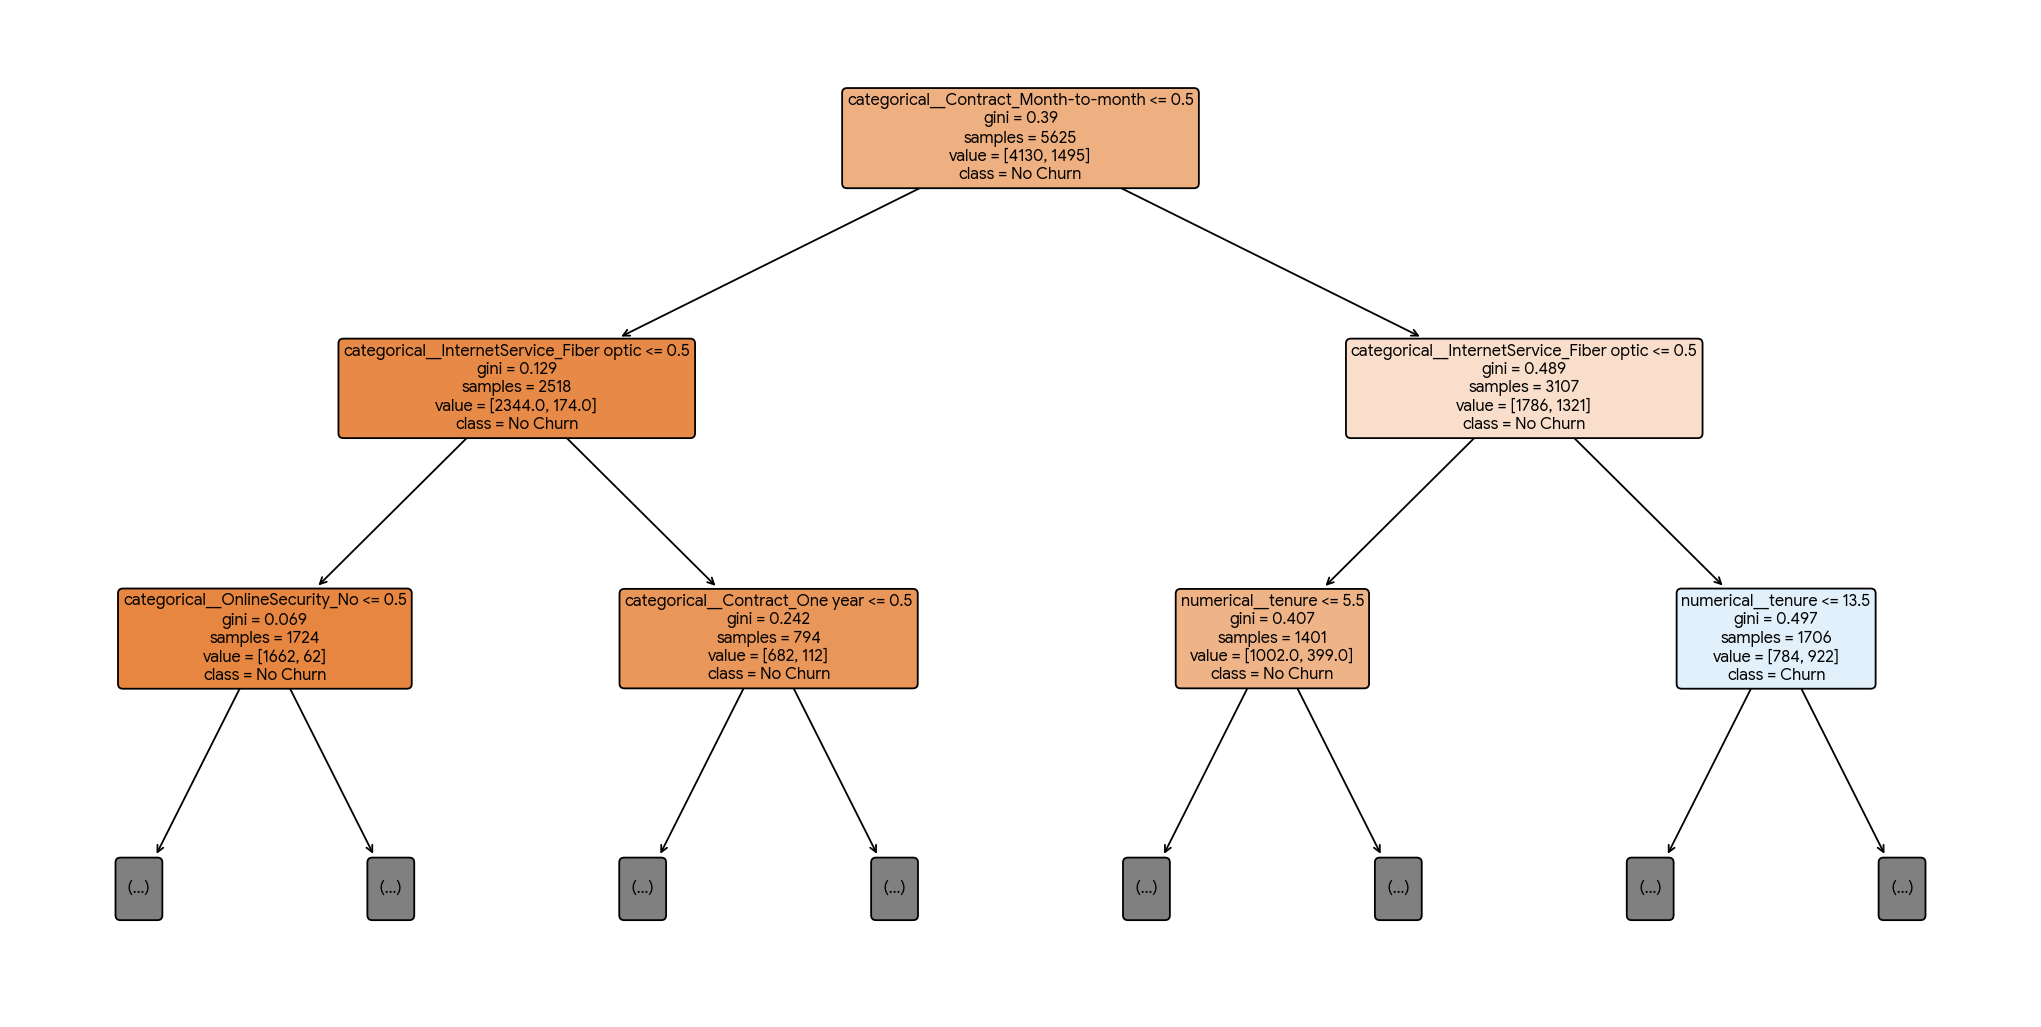

In [42]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Visualize the Decision Tree that we already trained.
# Display only the first three levels to keep the diagram readable.
plt.figure(figsize=(20, 10))

plot_tree(
    feature_tree_pipeline.named_steps['model'],
    feature_names=feature_names,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.show()

# Grid search suggested by Peleke

In [43]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter values we want GridSearchCV to test.
# The "model__" prefix tells scikit-learn that these parameters
# belong to the DecisionTreeClassifier inside the pipeline.

param_grid = {
    'model__max_depth': [3, 4, 5, 6, 8],
    'model__min_samples_leaf': [5, 10, 20, 40],
    'model__class_weight': [None, 'balanced']
}

# Display the hyperparameters we plan to test.
print(param_grid)

{'model__max_depth': [3, 4, 5, 6, 8], 'model__min_samples_leaf': [5, 10, 20, 40], 'model__class_weight': [None, 'balanced']}


In [44]:
from sklearn.metrics import f1_score

# Create a custom scoring function that uses the 0.30 threshold.
# GridSearchCV will use this function to evaluate each model.

def churn_f1_score(model, X, y_true):

    # Get the predicted probability of churn for each customer.
    probabilities = model.predict_proba(X)[:, 1]

    # Convert probabilities into predictions using the threshold.
    predictions = (probabilities >= 0.30).astype(int)

    # Compare predictions with actual churn outcomes.
    return f1_score(y_true, predictions)

In [45]:
# Search for the best combination of Decision Tree hyperparameters.
# Use the custom F1 scorer with a classification threshold of 0.30.

grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=param_grid,
    scoring=churn_f1_score,
    cv=cv,
    n_jobs=1
)

# Train and evaluate all hyperparameter combinations
# using only the training dataset.
grid_search.fit(X_train, y_train)

# Display the best hyperparameter combination and its average F1-score.
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best Mean F1-score: {grid_search.best_score_:.4f}")

Best Hyperparameters: {'model__class_weight': None, 'model__max_depth': 6, 'model__min_samples_leaf': 40}
Best Mean F1-score: 0.6237


In [46]:
# Evaluate the Decision Tree selected by the F1 GridSearchCV.
# Use 5-fold cross-validation on the training data.

# Get predicted churn probabilities from the optimized model.
f1_probabilities = cross_val_predict(
    grid_search.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

# Apply the chosen classification threshold of 0.30.
f1_predictions = (f1_probabilities >= 0.30).astype(int)

# Display the selected hyperparameters and evaluation scores.
print("F1-Optimized Decision Tree")
print("Best Hyperparameters:", grid_search.best_params_)
print()
print(f"Precision: {precision_score(y_train, f1_predictions):.4f}")
print(f"Recall:    {recall_score(y_train, f1_predictions):.4f}")
print(f"F1-score:  {f1_score(y_train, f1_predictions):.4f}")
print(f"Accuracy:  {accuracy_score(y_train, f1_predictions):.4f}")

F1-Optimized Decision Tree
Best Hyperparameters: {'model__class_weight': None, 'model__max_depth': 6, 'model__min_samples_leaf': 40}

Precision: 0.5358
Recall:    0.7458
F1-score:  0.6236
Accuracy:  0.7607


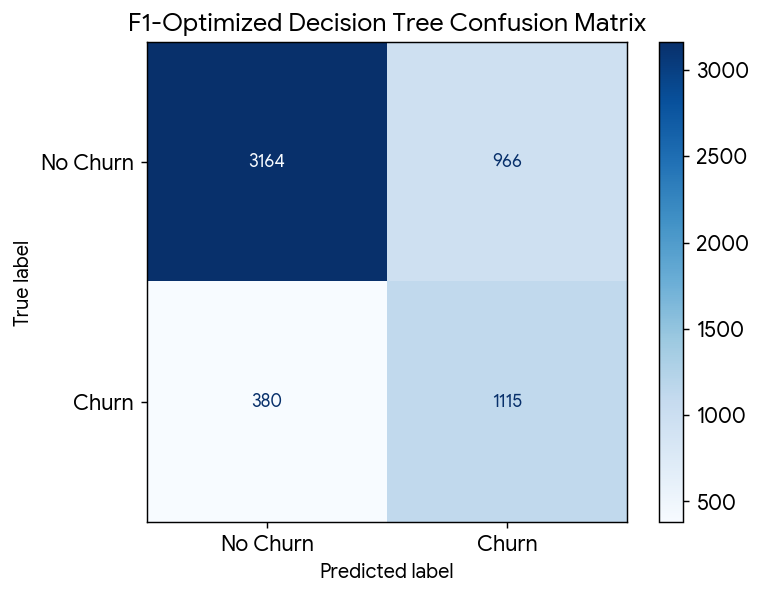

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Visualize the predictions from the F1-optimized Decision Tree.
# These predictions were generated using 5-fold cross-validation.

ConfusionMatrixDisplay.from_predictions(
    y_train,
    f1_predictions,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues',
    values_format='d'
)

plt.title('F1-Optimized Decision Tree Confusion Matrix')
plt.show()

In [48]:
# Fit the actual best Decision Tree selected by GridSearchCV.
# This avoids manually hard-coding parameters that may differ from the search result.
optimized_tree_pipeline = grid_search.best_estimator_
optimized_tree_pipeline.fit(X_train, y_train)

# Get the feature names after preprocessing and one-hot encoding.
feature_names = optimized_tree_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = optimized_tree_pipeline.named_steps['model'].feature_importances_
optimized_tree_importance = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print('Best parameters:', grid_search.best_params_)
print(optimized_tree_importance.head(15))


Best parameters: {'model__class_weight': None, 'model__max_depth': 6, 'model__min_samples_leaf': 40}
categorical__Contract_Month-to-month           0.477301
numerical__tenure                              0.181615
categorical__InternetService_Fiber optic       0.152340
numerical__TotalCharges                        0.031749
categorical__TechSupport_No                    0.031157
numerical__MonthlyCharges                      0.031062
categorical__PaymentMethod_Electronic check    0.021865
numerical__SeniorCitizen                       0.013284
categorical__OnlineSecurity_No                 0.008188
categorical__PhoneService_No                   0.008131
categorical__Contract_One year                 0.007946
categorical__StreamingMovies_No                0.007412
categorical__PaperlessBilling_Yes              0.006738
categorical__MultipleLines_No                  0.005905
categorical__MultipleLines_Yes                 0.004650
dtype: float64


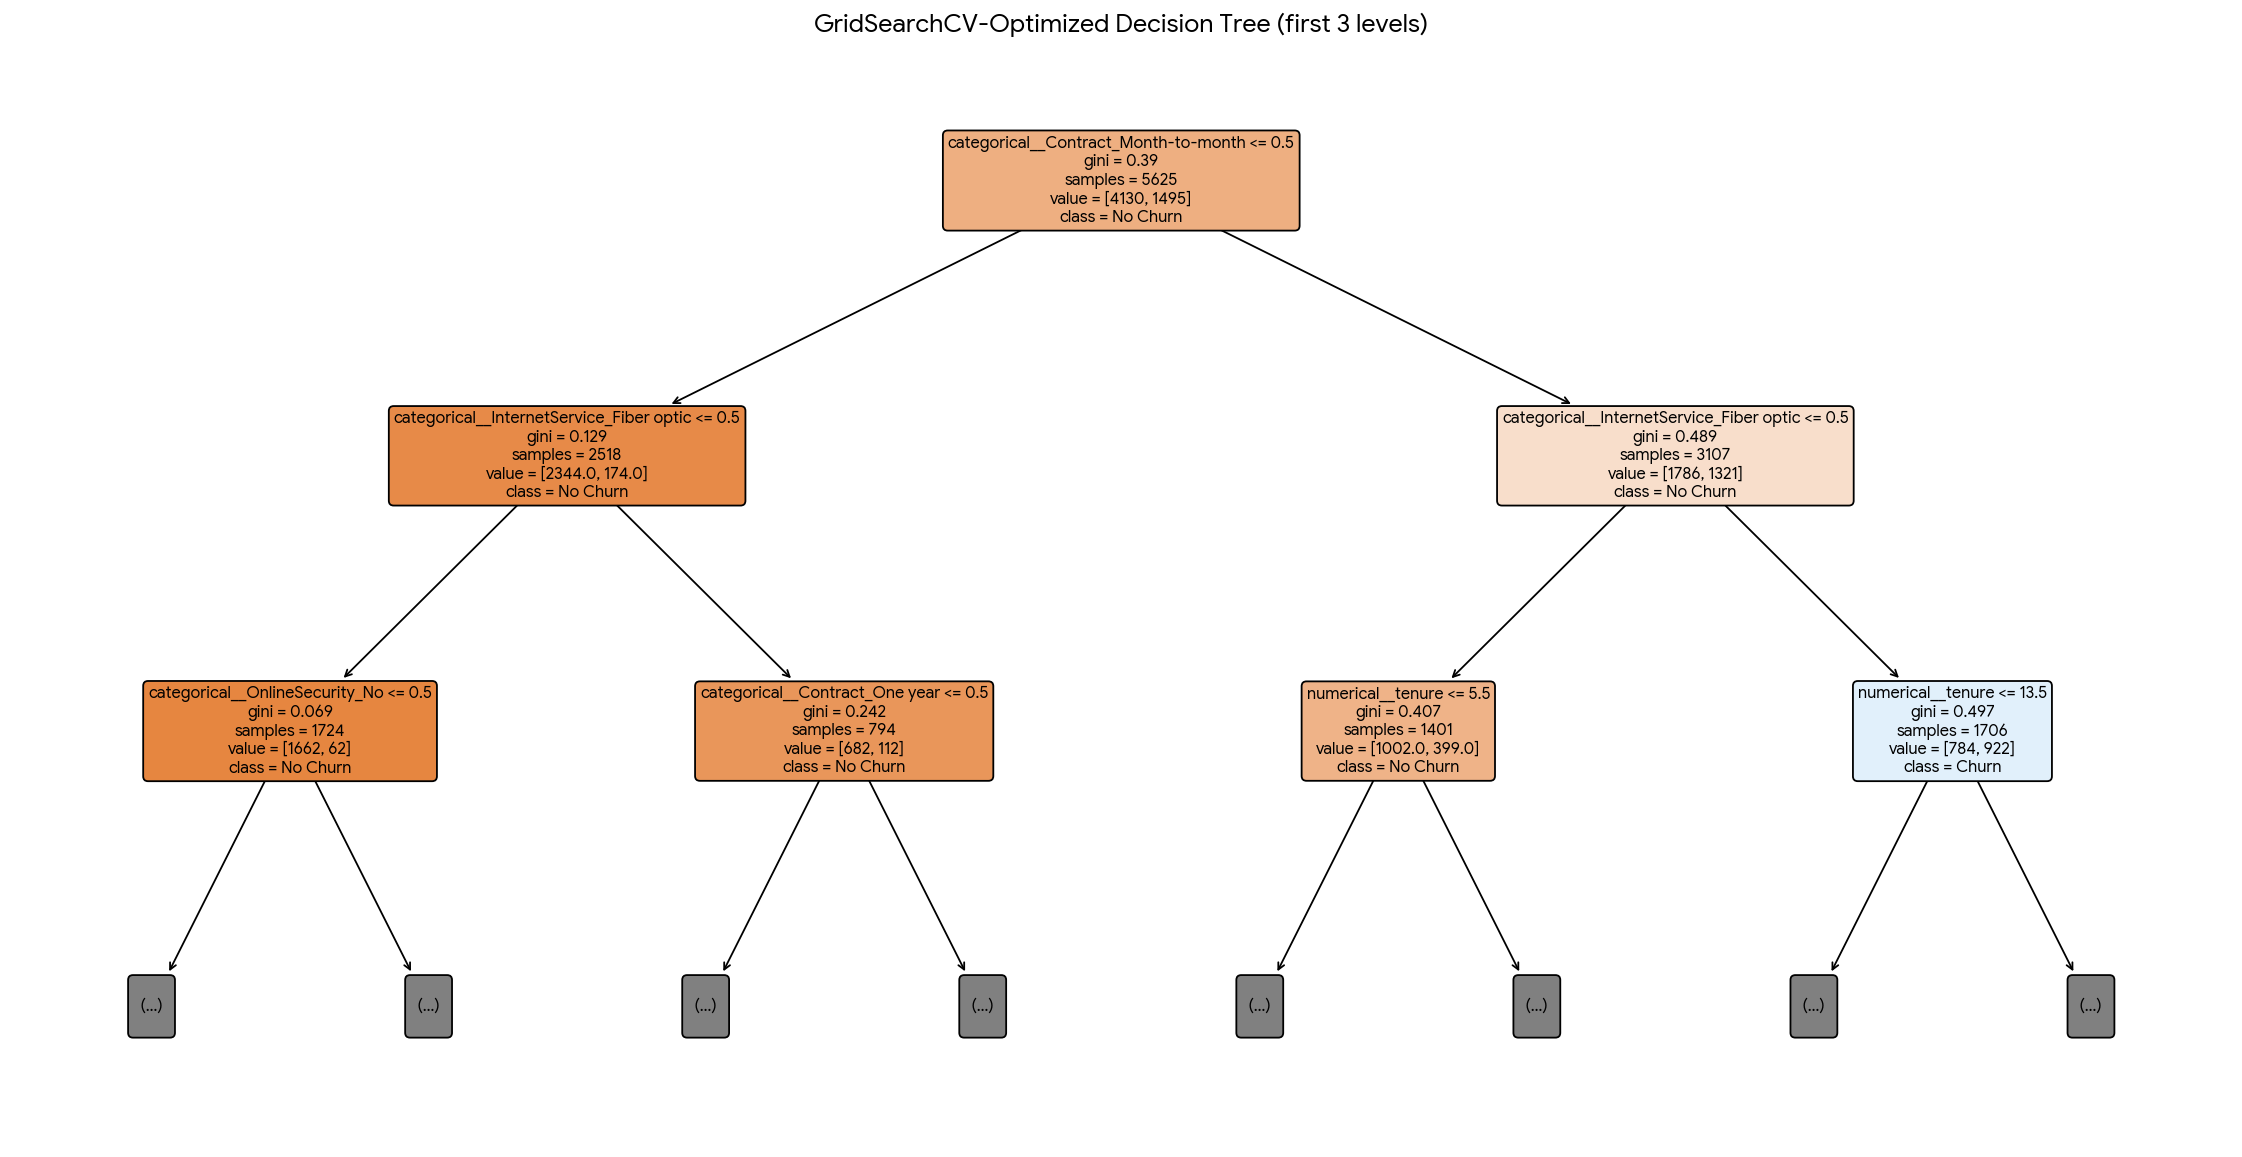

In [49]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 11))
plot_tree(
    optimized_tree_pipeline.named_steps['model'],
    feature_names=feature_names,
    class_names=['No Churn', 'Churn'],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)
plt.title('GridSearchCV-Optimized Decision Tree (first 3 levels)')
plt.show()


## Final model comparison and project conclusion

The next sections complete the project by adding Random Forest and an MLP neural network, comparing all four models using the same stratified 5-fold cross-validation procedure, and evaluating the final fitted models once on the untouched 20% holdout test set.

**Do not report training/CV results as test results.** The holdout test set is reserved for the final comparison.


## 1. Random Forest — model training and tuning

Random Forest combines many decision trees. It can capture nonlinear relationships and interactions between customer features. We tune a small, practical parameter grid using only the training set and 5-fold cross-validation.

In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

random_forest_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=88,
        n_jobs=-1,
        class_weight='balanced_subsample'
    ))
])

rf_param_grid = {
    'model__n_estimators': [300],
    'model__max_depth': [None, 12],
    'model__min_samples_leaf': [1, 5],
    'model__max_features': ['sqrt']
}

rf_grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    refit=True
)
rf_grid_search.fit(X_train, y_train)

print('Random Forest best parameters:', rf_grid_search.best_params_)
print(f'Random Forest best mean CV ROC-AUC: {rf_grid_search.best_score_:.4f}')


Random Forest best parameters: {'model__max_depth': 12, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
Random Forest best mean CV ROC-AUC: 0.8412


## 2. MLP Neural Network — model training

An MLP (multilayer perceptron) is a feed-forward neural network. We scale numerical variables because neural networks are sensitive to feature scales. The one-hot encoding and scaling are kept inside a pipeline so each CV fold learns preprocessing only from its own training portion.

In [51]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

mlp_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('numerical', StandardScaler(), numerical_cols)
    ]
)

mlp_pipeline = Pipeline(steps=[
    ('preprocessor', mlp_preprocessor),
    ('model', MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=88
    ))
])

print(mlp_pipeline)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'], dtype='object')),
                                                 ('numerical', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object'))])),
                ('model',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(64, 32), max_iter=300,
                               n_iter_no_change=20, random_state=88))])


## 3. Consistent cross-validation comparison

All four models are evaluated with the same 5-fold stratified CV on the training data. We report ROC-AUC from predicted probabilities and Precision, Recall, F1, and Accuracy using a preselected probability threshold of 0.30. This threshold reflects the earlier Logistic Regression experiment's emphasis on finding more customers at risk of churn. It is not tuned on the holdout test set.

In [52]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report
)

final_models = {
    'Logistic Regression': logistic_pipeline,
    'Decision Tree (GridSearchCV)': grid_search.best_estimator_,
    'Random Forest (GridSearchCV)': rf_grid_search.best_estimator_,
    'MLP Neural Network': mlp_pipeline
}

CHURN_THRESHOLD = 0.30
cv_rows = []
cv_probabilities = {}

for model_name, estimator in final_models.items():
    print(f'Running 5-fold out-of-fold predictions: {model_name}')
    probabilities = cross_val_predict(
        estimator, X_train, y_train,
        cv=cv, method='predict_proba', n_jobs=-1
    )[:, 1]
    predictions = (probabilities >= CHURN_THRESHOLD).astype(int)
    cv_probabilities[model_name] = probabilities

    cv_rows.append({
        'Model': model_name,
        'Threshold': CHURN_THRESHOLD,
        'Accuracy': accuracy_score(y_train, predictions),
        'Precision': precision_score(y_train, predictions, zero_division=0),
        'Recall': recall_score(y_train, predictions, zero_division=0),
        'F1': f1_score(y_train, predictions, zero_division=0),
        'ROC_AUC': roc_auc_score(y_train, probabilities)
    })

cv_comparison = pd.DataFrame(cv_rows).sort_values('F1', ascending=False)
display(cv_comparison.round(4))
cv_comparison.to_csv('cross_validation_model_results.csv', index=False)


Running 5-fold out-of-fold predictions: Logistic Regression
Running 5-fold out-of-fold predictions: Decision Tree (GridSearchCV)
Running 5-fold out-of-fold predictions: Random Forest (GridSearchCV)
Running 5-fold out-of-fold predictions: MLP Neural Network


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.3,0.7646,0.5407,0.7599,0.6318,0.8428
1,Decision Tree (GridSearchCV),0.3,0.7607,0.5358,0.7458,0.6236,0.8286
3,MLP Neural Network,0.3,0.7646,0.5425,0.7298,0.6224,0.8320
2,Random Forest (GridSearchCV),0.3,0.6789,0.4475,0.8863,0.5947,0.8405


## 4. Final holdout test evaluation

The models are now fitted on the full 80% training split and evaluated on the untouched 20% test split. The test set is not used for parameter selection or threshold selection. For transparency, the table shows both the standard 0.50 threshold and the project's 0.30 threshold.

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt
import joblib

holdout_rows = []
fitted_models = {}
holdout_probabilities = {}

for model_name, estimator in final_models.items():
    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    fitted_models[model_name] = fitted

    probabilities = fitted.predict_proba(X_test)[:, 1]
    holdout_probabilities[model_name] = probabilities

    for threshold in [0.50, CHURN_THRESHOLD]:
        predictions = (probabilities >= threshold).astype(int)
        holdout_rows.append({
            'Model': model_name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_test, predictions),
            'Precision': precision_score(y_test, predictions, zero_division=0),
            'Recall': recall_score(y_test, predictions, zero_division=0),
            'F1': f1_score(y_test, predictions, zero_division=0),
            'ROC_AUC': roc_auc_score(y_test, probabilities)
        })

holdout_results = pd.DataFrame(holdout_rows)
display(holdout_results.round(4))
holdout_results.to_csv('final_holdout_model_results.csv', index=False)

# Save fitted models so they can be reused without retraining.
joblib.dump(fitted_models, 'telco_churn_four_models.joblib')
print('Saved: final_holdout_model_results.csv')
print('Saved: cross_validation_model_results.csv')
print('Saved: telco_churn_four_models.joblib')


Saved: final_holdout_model_results.csv
Saved: cross_validation_model_results.csv
Saved: telco_churn_four_models.joblib


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.5,0.8031,0.6511,0.5588,0.6014,0.8509
1,Logistic Regression,0.3,0.7619,0.5355,0.7861,0.6371,0.8509
2,Decision Tree (GridSearchCV),0.5,0.7953,0.6236,0.5802,0.6011,0.8403
3,Decision Tree (GridSearchCV),0.3,0.7584,0.5326,0.7433,0.6205,0.8403
4,Random Forest (GridSearchCV),0.5,0.7733,0.5540,0.7540,0.6387,0.8551
5,Random Forest (GridSearchCV),0.3,0.7043,0.4704,0.8930,0.6162,0.8551
6,MLP Neural Network,0.5,0.7982,0.6301,0.5829,0.6056,0.8461
7,MLP Neural Network,0.3,0.7591,0.5322,0.7727,0.6303,0.8461


## 5. Confusion matrices and ROC curves

A confusion matrix shows correct and incorrect churn classifications. The ROC curve compares true-positive and false-positive rates across thresholds. ROC-AUC summarizes ranking ability and does not depend on one fixed threshold.

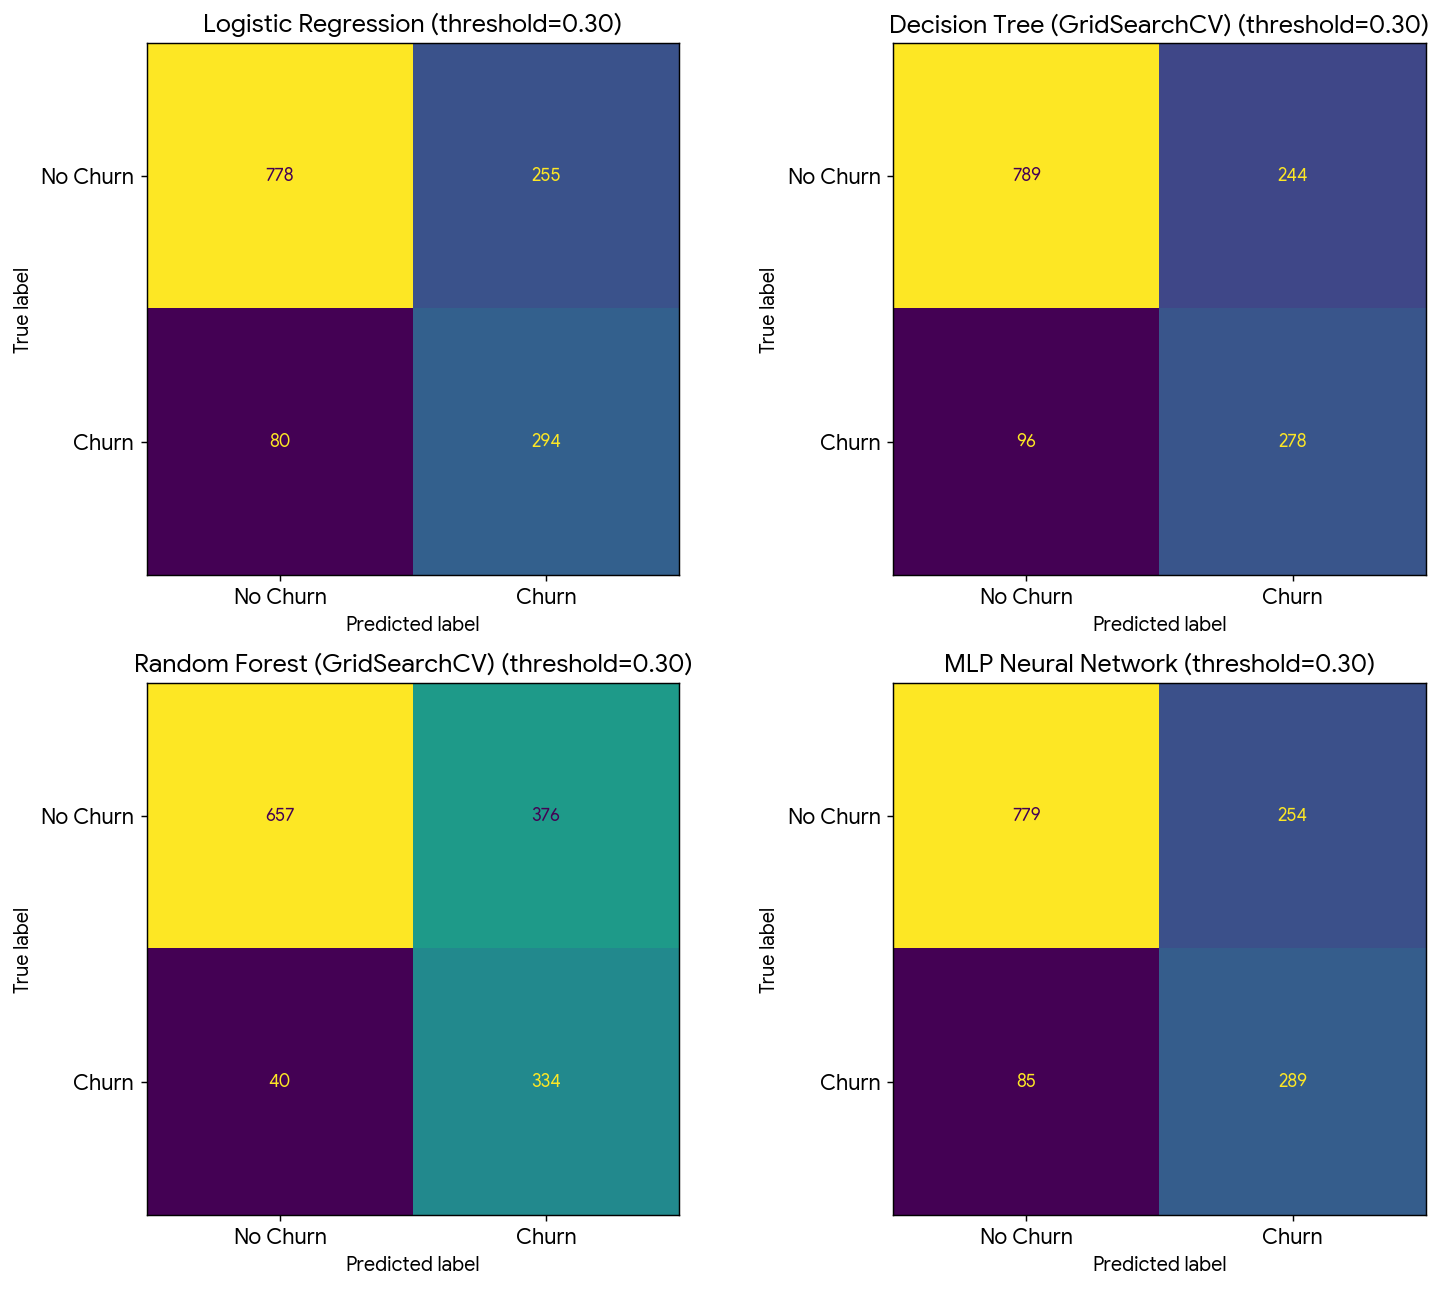

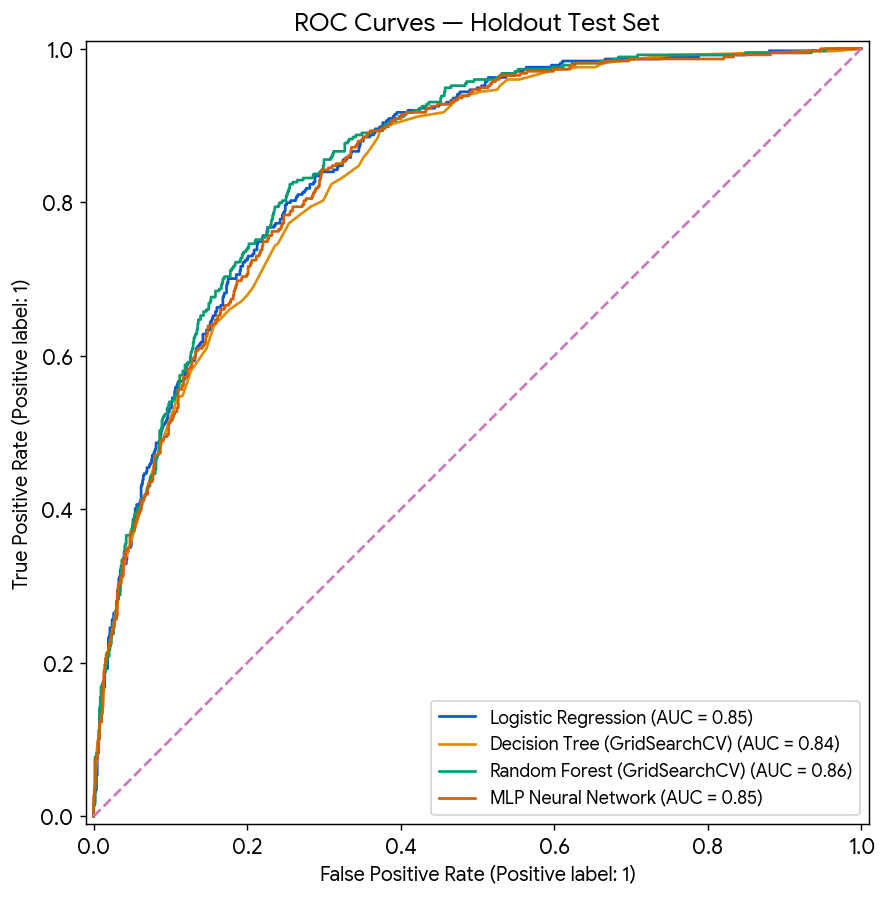

In [54]:
# Confusion matrices at the project's 0.30 threshold.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (model_name, probabilities) in zip(axes.ravel(), holdout_probabilities.items()):
    predictions = (probabilities >= CHURN_THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        display_labels=['No Churn', 'Churn'],
        values_format='d',
        ax=ax,
        colorbar=False
    )
    ax.set_title(f'{model_name} (threshold={CHURN_THRESHOLD:.2f})')
plt.tight_layout()
plt.show()

# ROC curves.
fig, ax = plt.subplots(figsize=(9, 7))
for model_name, fitted in fitted_models.items():
    RocCurveDisplay.from_estimator(fitted, X_test, y_test, ax=ax, name=model_name)
ax.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
ax.set_title('ROC Curves — Holdout Test Set')
plt.tight_layout()
plt.show()


## 6. Feature importance and interpretation

Tree-based models provide impurity-based feature importance. These values indicate which encoded features the model used most for its splits; they do not prove causation. Logistic Regression coefficients can also be inspected, but their signs and magnitudes depend on encoding and feature scaling.

Top 15 Random Forest features:
Top 15 Decision Tree features:


,Importance
numerical__tenure,0.133154
categorical__Contract_Month-to-month,0.128773
numerical__TotalCharges,0.107234
numerical__MonthlyCharges,0.076992
categorical__Contract_Two year,0.050910
categorical__TechSupport_No,0.050065
categorical__OnlineSecurity_No,0.049550
categorical__PaymentMethod_Electronic check,0.043388
categorical__InternetService_Fiber optic,0.034909
categorical__OnlineBackup_No,0.020813


,Importance
categorical__Contract_Month-to-month,0.477301
numerical__tenure,0.181615
categorical__InternetService_Fiber optic,0.152340
numerical__TotalCharges,0.031749
categorical__TechSupport_No,0.031157
numerical__MonthlyCharges,0.031062
categorical__PaymentMethod_Electronic check,0.021865
numerical__SeniorCitizen,0.013284
categorical__OnlineSecurity_No,0.008188
categorical__PhoneService_No,0.008131


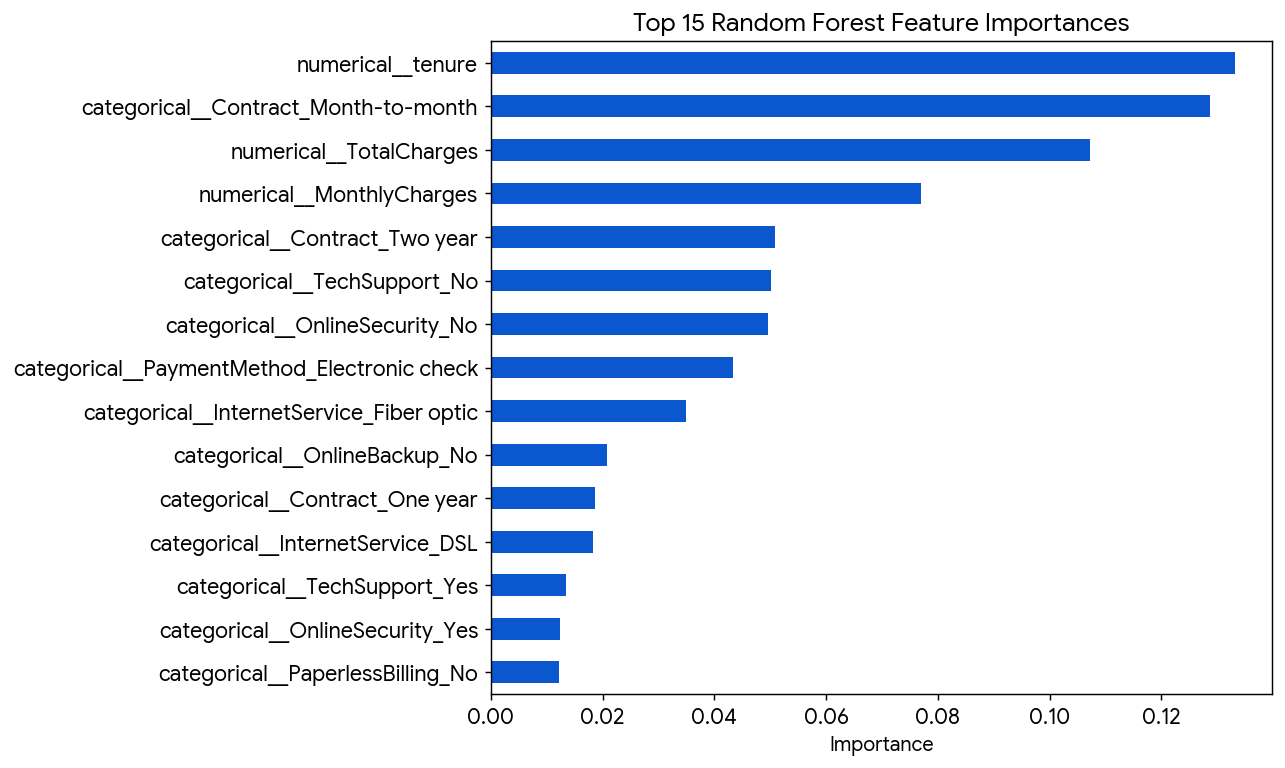

In [55]:
# Random Forest feature importance.
rf_fitted = fitted_models['Random Forest (GridSearchCV)']
rf_feature_names = rf_fitted.named_steps['preprocessor'].get_feature_names_out()
rf_importances = rf_fitted.named_steps['model'].feature_importances_
rf_importance = pd.Series(rf_importances, index=rf_feature_names).sort_values(ascending=False)

print('Top 15 Random Forest features:')
display(rf_importance.head(15).to_frame('Importance'))

plt.figure(figsize=(10, 6))
rf_importance.head(15).sort_values().plot(kind='barh')
plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

# Decision Tree feature importance from the tuned model.
dt_fitted = fitted_models['Decision Tree (GridSearchCV)']
dt_feature_names = dt_fitted.named_steps['preprocessor'].get_feature_names_out()
dt_importance = pd.Series(
    dt_fitted.named_steps['model'].feature_importances_,
    index=dt_feature_names
).sort_values(ascending=False)

print('Top 15 Decision Tree features:')
display(dt_importance.head(15).to_frame('Importance'))
